# `feels` — Signal Cleaning & Content Discrimination

**Goal:** given the joint-torque telemetry recorded while the xArm850 picks up an *opaque lidded cup*, figure out **what's inside** — `empty`, `water`, `candy`, etc. — from proprioception alone.

This notebook does two things:

1. **Clean the signals.** The raw torque stream is noisy, has a per-pose gravity bias, and is segmented into motion *phases*. We tare it, smooth it, and isolate the phase that actually carries information.
2. **Find discriminators.** We extract physically-motivated features and show, with clear visuals, *which* features separate the classes — and which don't.

> **Reality check on sampling rate.** The recordings sample at **~3.7 Hz** (WebRTC latency cap). Nyquist ≈ 1.85 Hz, so they can only reveal **static mass** and **low-frequency slosh** — *not* the 5–25 Hz "rattle" of loose candy. Resolving water vs soap vs candy needs ≥100 Hz data from the on-robot `control_service.py`; the final section shows why.

---
## Section 0 — Setup

In [75]:
import glob, os, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.signal import butter, filtfilt, welch

plt.rcParams.update({
    "figure.figsize": (12, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "axes.titleweight": "bold",
})

# Repo layout: this notebook lives in notebooks/, data in ../recordings/
REC_DIR = Path("..") / "recordings"

# Consistent color per content class
CLASS_COLORS = {
    "empty_cup":      "#9e9e9e",
    "water_half":     "#1f77b4",
    "dish_soap_half": "#17bec8",
    "candy_mixed":    "#ff7f0e",
    "candy_loose":    "#ff7f0e",
    "solid_weight":   "#d62728",
    "mystery":        "#9467bd",
}
def ccolor(label): return CLASS_COLORS.get(label, "#333333")

print("recordings dir exists:", REC_DIR.exists())

recordings dir exists: True


---
## Section 1 — Load & inventory the real recordings

Each real recording is one full pick-and-place cycle. Columns of interest:

| column | meaning |
|---|---|
| `elapsed_sec` | time since recording start |
| `phase` | motion phase label (`INIT` → `REACH_GRASP` → … → `RETURN_HOME`) |
| `object_label` | ground-truth contents |
| `tau1_nm … tau6_nm` | per-joint actuator torque (N·m) — **our signal** |
| `tcp_z_mm` | tool height (useful to see lift/descend) |
| `gripper_holding`, `gripper_pos` | grasp state |

Physics: in this posture **Joint 3 (elbow)** is a horizontal cantilever, so payload weight shows up as a clean shift in `tau3_nm`. Joint 2 (shoulder) carries the big gravity term.

In [76]:
def load_recording(path):
    df = pd.read_csv(path)
    df["source"] = os.path.basename(path)
    return df

rec_files = sorted(glob.glob(str(REC_DIR / "recording_*.csv")))
recs = {os.path.basename(f): load_recording(f) for f in rec_files}

inv = pd.DataFrame([{
    "file": name,
    "label": df["object_label"].iloc[0],
    "samples": len(df),
    "duration_s": round(df["elapsed_sec"].iloc[-1], 1),
    "rate_hz": round(1.0 / df["elapsed_sec"].diff().median(), 2),
    "tau3_min": round(df["tau3_nm"].min(), 2),
    "tau3_max": round(df["tau3_nm"].max(), 2),
} for name, df in recs.items()])
inv

,file,label,samples,duration_s,rate_hz,tau3_min,tau3_max
0,recording_20261029_153038_water_half.csv,water_half,142,40.6,3.66,-21.64,-7.16
1,recording_20261029_153510_empty_cup.csv,empty_cup,129,38.2,3.65,-17.64,-7.16
2,recording_20261029_153756_mystery.csv,mystery,126,38.5,3.66,-18.11,-5.82
3,recording_20261029_154108_candy_mixed.csv,candy_mixed,128,37.5,3.69,-17.83,-7.07
4,recording_20261029_154553_candy_mixed.csv,candy_mixed,110,37.7,3.66,-17.51,-6.57
5,recording_20261029_154729_empty_cup.csv,empty_cup,131,38.4,3.69,-18.11,-6.70


---
## Section 2 — Raw signal + phase structure

Before cleaning anything, look at the raw `tau3` and `tau2` traces, shaded by motion phase. Two things jump out:

- The signal is **dominated by the motion itself** (the arm swinging through approach/lift/descend), not by the payload.
- There is one quiet window — **`TRAVEL_STABLE_HOLD`** — where the arm holds the cup still. *That* is where the payload signature is cleanest.

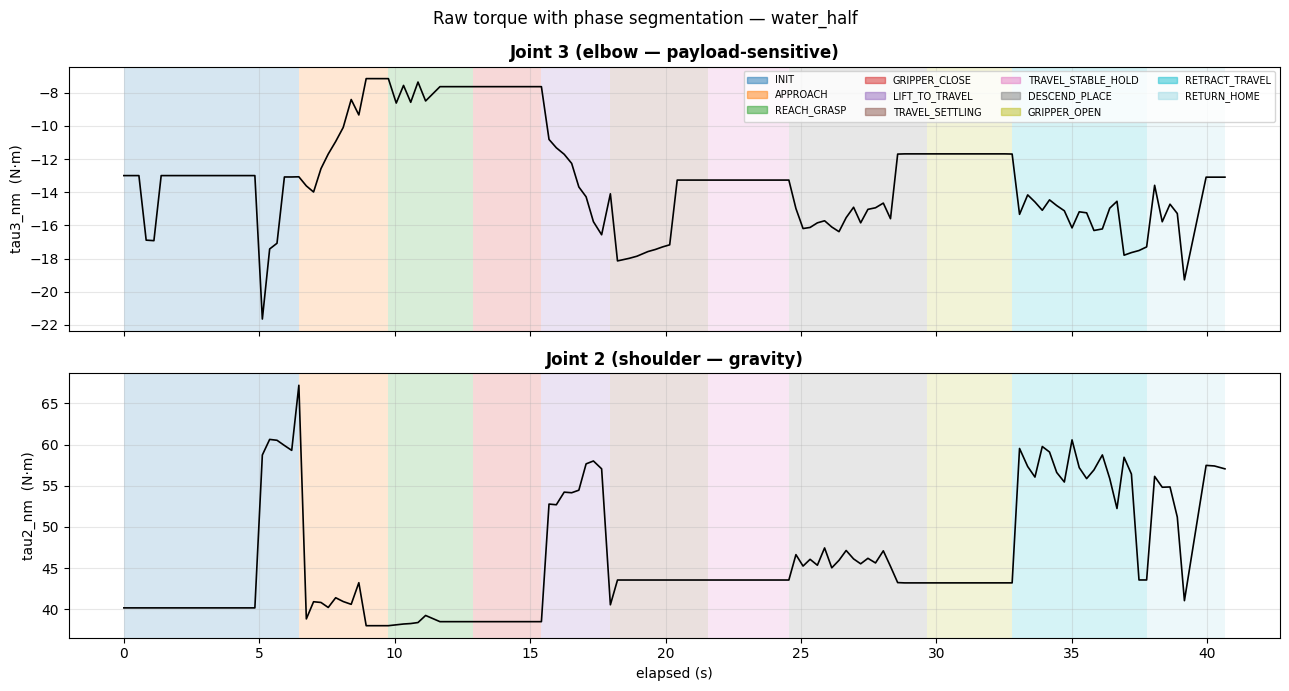

In [77]:
PHASES = ["INIT","APPROACH","REACH_GRASP","GRIPPER_CLOSE","LIFT_TO_TRAVEL",
          "TRAVEL_SETTLING","TRAVEL_STABLE_HOLD","DESCEND_PLACE","GRIPPER_OPEN",
          "RETRACT_TRAVEL","RETURN_HOME"]
PHASE_CMAP = plt.cm.tab20(np.linspace(0, 1, len(PHASES)))
PHASE_COLOR = {p: PHASE_CMAP[i] for i, p in enumerate(PHASES)}
HOLD_PHASE = "TRAVEL_STABLE_HOLD"

def shade_phases(ax, df):
    t = df["elapsed_sec"].values
    ph = df["phase"].values
    start = 0
    for i in range(1, len(ph) + 1):
        if i == len(ph) or ph[i] != ph[start]:
            ax.axvspan(t[start], t[min(i, len(t)-1)],
                       color=PHASE_COLOR.get(ph[start], "#ccc"), alpha=0.18, lw=0)
            start = i

# Show one representative recording with full phase shading
ex_name = next(n for n, d in recs.items() if d["object_label"].iloc[0] == "water_half")
ex = recs[ex_name]

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, col, ttl in zip(axes, ["tau3_nm","tau2_nm"],
                        ["Joint 3 (elbow — payload-sensitive)","Joint 2 (shoulder — gravity)"]):
    shade_phases(ax, ex)
    ax.plot(ex["elapsed_sec"], ex[col], color="k", lw=1.2)
    ax.set_ylabel(f"{col}  (N·m)"); ax.set_title(ttl)
axes[1].set_xlabel("elapsed (s)")
handles = [Patch(color=PHASE_COLOR[p], alpha=0.5, label=p) for p in PHASES]
axes[0].legend(handles=handles, ncol=4, fontsize=7, loc="upper right")
fig.suptitle(f"Raw torque with phase segmentation — {ex['object_label'].iloc[0]}", y=0.98)
plt.tight_layout(); plt.show()

---
## Section 3 — Cleaning the signal

Three cleaning steps, visualized:

1. **Tare (baseline removal).** Subtract the median `tau3` during `INIT` (arm empty, before grasp). Converts absolute torque into **Δτ₃ = payload-induced torque**, removing the per-pose gravity bias.
2. **Smoothing.** Compare the repo's EMA (α=0.35) against a **zero-phase Butterworth low-pass** (`filtfilt`, no lag). EMA is cheap/online; Butterworth is cleaner for offline feature extraction.
3. **Phase isolation.** Keep only the `TRAVEL_STABLE_HOLD` window for the static-mass feature.

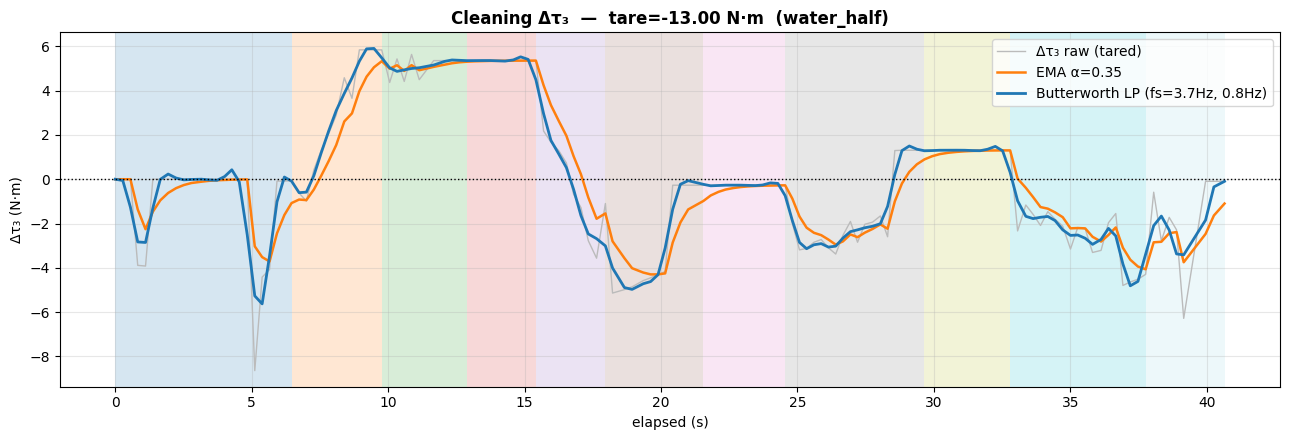

sampling rate ≈ 3.66 Hz  →  Nyquist ≈ 1.83 Hz (no 5–25 Hz rattle visible here)


In [78]:
def tare_value(df, col="tau3_nm", phase="INIT"):
    init = df.loc[df["phase"] == phase, col]
    return init.median() if len(init) else df[col].iloc[:5].median()

def ema(x, alpha=0.35):
    out = np.empty_like(x, dtype=float); out[0] = x[0]
    for i in range(1, len(x)):
        out[i] = alpha * x[i] + (1 - alpha) * out[i-1]
    return out

def butter_lowpass(x, fs, cutoff_hz, order=2):
    # cutoff must be < Nyquist; guard for short / slow signals
    nyq = fs / 2.0
    wc = min(cutoff_hz, 0.9 * nyq) / nyq
    b, a = butter(order, wc, btype="low")
    padlen = 3 * max(len(a), len(b))
    if len(x) <= padlen:
        return x.astype(float)
    return filtfilt(b, a, x)

# Demonstrate on the example recording
df = ex.copy()
fs = 1.0 / df["elapsed_sec"].diff().median()
tare = tare_value(df)
raw = df["tau3_nm"].values
delta_raw = raw - tare
delta_ema = ema(delta_raw, 0.35)
delta_butter = butter_lowpass(delta_raw, fs, cutoff_hz=0.8)

fig, ax = plt.subplots(figsize=(13, 4.5))
shade_phases(ax, df)
ax.plot(df["elapsed_sec"], delta_raw,    color="#bbb", lw=1,   label="Δτ₃ raw (tared)")
ax.plot(df["elapsed_sec"], delta_ema,    color="#ff7f0e", lw=1.8, label="EMA α=0.35")
ax.plot(df["elapsed_sec"], delta_butter, color="#1f77b4", lw=2,   label=f"Butterworth LP (fs={fs:.1f}Hz, 0.8Hz)")
ax.axhline(0, color="k", ls=":", lw=1)
ax.set_title(f"Cleaning Δτ₃  —  tare={tare:.2f} N·m  ({df['object_label'].iloc[0]})")
ax.set_xlabel("elapsed (s)"); ax.set_ylabel("Δτ₃ (N·m)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
print(f"sampling rate ≈ {fs:.2f} Hz  →  Nyquist ≈ {fs/2:.2f} Hz (no 5–25 Hz rattle visible here)")

### Cleaned Δτ₃ for every recording, overlaid

Same cleaning applied to all recordings. The **stable-hold band** is highlighted — notice the different plateau heights (that's mass) and the different amounts of wobble within the band (that's slosh / shifting contents).

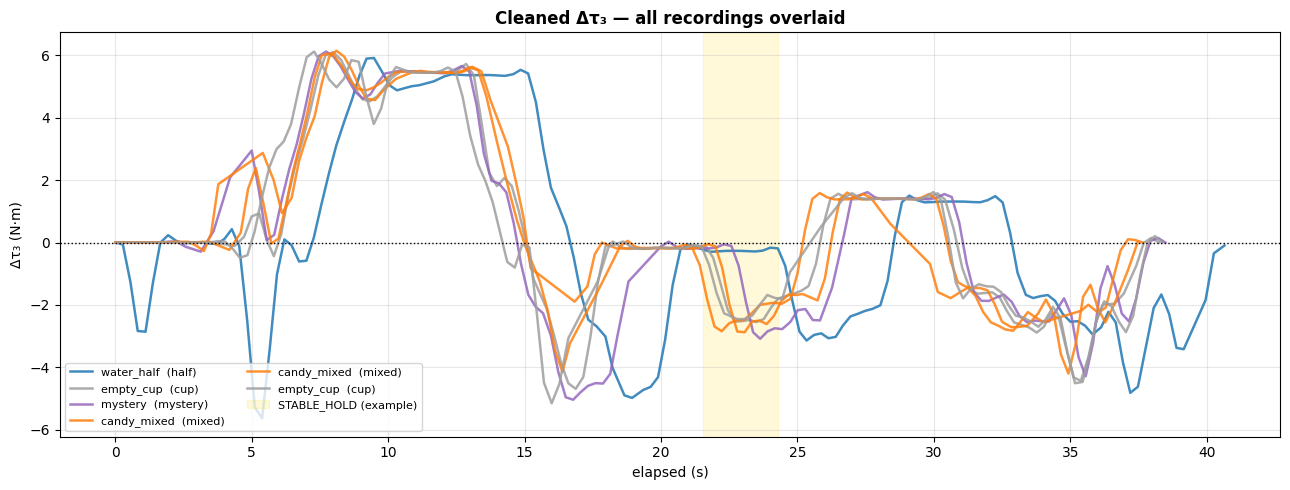

In [79]:
JOINTS = list(range(1, 7))   # xArm850 is 6-DOF — use ALL internal joint torques

def add_clean(df):
    df = df.copy()
    fs = 1.0 / df["elapsed_sec"].diff().median()
    for j in JOINTS:
        col = f"tau{j}_nm"
        tare = tare_value(df, col=col)         # per-joint INIT baseline
        df[f"dtau{j}"]   = df[col].values - tare
        df[f"dtau{j}_s"] = butter_lowpass(df[f"dtau{j}"].values, fs, 0.8)
    # convenience aliases for the single-channel (elbow) views used elsewhere
    df["delta_tau3"], df["delta_tau3_s"] = df["dtau3"], df["dtau3_s"]
    df.attrs["fs"] = fs
    return df

clean = {n: add_clean(d) for n, d in recs.items()}

fig, ax = plt.subplots(figsize=(13, 5))
for n, d in clean.items():
    lab = d["object_label"].iloc[0]
    ax.plot(d["elapsed_sec"], d["delta_tau3_s"], color=ccolor(lab), lw=1.8,
            label=f"{lab}  ({n.split('_')[-1].replace('.csv','')})", alpha=0.85)
# shade the hold window of the example for reference
hold = ex[ex["phase"] == HOLD_PHASE]["elapsed_sec"]
if len(hold):
    ax.axvspan(hold.iloc[0], hold.iloc[-1], color="gold", alpha=0.15,
               label="STABLE_HOLD (example)")
ax.axhline(0, color="k", ls=":", lw=1)
ax.set_title("Cleaned Δτ₃ — all recordings overlaid")
ax.set_xlabel("elapsed (s)"); ax.set_ylabel("Δτ₃ (N·m)")
ax.legend(ncol=2, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

---
## Section 4 — Feature extraction from the internal joint signals

We use the robot's **internal proprioception** only — the six actuator torques Δτ₁…Δτ₆ (tared, N·m). No external sensor, no mass conversion. For every joint we summarise two regimes:

- **hold** (`TRAVEL_STABLE_HOLD`): `hold_tauJ` = mean torque → static load carried by that joint.
- **motion** (`LIFT_TO_TRAVEL` + `DESCEND_PLACE`): `dyn_tauJ` = torque std → inertia / slosh that joint feels while swinging.

Plus three elbow-specific shape features (`hold_wobble`, `hold_ptp`, `settle_slope`). `dyn_energy` is kept as an alias of `dyn_tau3` for the 2-D views.

In [80]:
# Internal joint signals only — directly measured torque (N·m). No grams, no
# lever-arm assumption: τJ is what each actuator actually reports.

def phase_slice(df, phase):
    return df[df["phase"] == phase]

DYN_PHASES = ["LIFT_TO_TRAVEL", "DESCEND_PLACE"]

def extract_features(df):
    feat = {"label": df["object_label"].iloc[0]}
    hold_mask = df["phase"] == HOLD_PHASE
    dyn_mask  = df["phase"].isin(DYN_PHASES)
    for j in JOINTS:                                  # ← all six joints
        h = df.loc[hold_mask, f"dtau{j}_s"].values
        if len(h) < 3:
            h = df[f"dtau{j}_s"].values[len(df)//2:]
        d = df.loc[dyn_mask, f"dtau{j}"].values
        feat[f"hold_tau{j}"] = round(float(np.mean(h)), 3)
        feat[f"dyn_tau{j}"]  = round(float(np.std(d)) if len(d) else 0.0, 4)
    # elbow (J3) shape detail
    h3 = df.loc[hold_mask, "dtau3_s"].values
    t3 = df.loc[hold_mask, "elapsed_sec"].values
    feat["hold_wobble"]  = round(float(np.std(h3)) if len(h3) else 0.0, 4)
    feat["hold_ptp"]     = round(float(np.ptp(h3)) if len(h3) else 0.0, 4)
    feat["settle_slope"] = round(float(np.polyfit(t3 - t3[0], h3, 1)[0]) if len(h3) > 2 else 0.0, 4)
    feat["hold_tau3_nm"] = feat["hold_tau3"]          # readable alias
    feat["dyn_energy"]   = feat["dyn_tau3"]
    return feat

feat = pd.DataFrame([{**{"file": n}, **extract_features(d)} for n, d in clean.items()])
feat = feat.sort_values("label").reset_index(drop=True)
feat

,file,label,hold_tau1,dyn_tau1,hold_tau2,dyn_tau2,hold_tau3,dyn_tau3,hold_tau4,dyn_tau4,hold_tau5,dyn_tau5,hold_tau6,dyn_tau6,hold_wobble,hold_ptp,settle_slope,hold_tau3_nm,dyn_energy
0,recording_20261029_154108_candy_mixed.csv,candy_mixed,-0.004,1.3078,3.315,5.2376,-0.163,2.0553,-0.035,0.3885,0.011,0.6930,0.001,0.5152,0.0422,0.1582,0.0340,-0.163,2.0553
1,recording_20261029_154553_candy_mixed.csv,candy_mixed,0.002,1.3182,-12.891,4.1881,-0.164,2.1936,-0.037,0.5316,0.013,0.7283,0.002,0.4624,0.0373,0.1296,0.0291,-0.164,2.1936
2,recording_20261029_153510_empty_cup.csv,empty_cup,-0.008,1.1708,-12.862,4.0638,-0.166,1.7104,-0.036,0.3532,0.014,0.6490,-0.000,0.4180,0.0333,0.1016,0.0303,-0.166,1.7104
3,recording_20261029_154729_empty_cup.csv,empty_cup,0.007,1.0233,3.318,5.6321,-0.144,2.2832,-0.037,0.3479,0.011,0.6915,0.001,0.3976,0.0654,0.2339,-0.0163,-0.144,2.2832
4,recording_20261029_153756_mystery.csv,mystery,0.006,1.9917,-10.746,5.4774,-0.234,1.9082,-0.034,0.5208,0.013,0.7485,0.001,0.2126,0.3266,1.2746,0.1951,-0.234,1.9082
5,recording_20261029_153038_water_half.csv,water_half,-0.000,0.9978,3.369,4.9990,-0.254,2.2028,-0.035,0.4500,0.013,0.7772,-0.000,0.4314,0.0403,0.1331,0.0256,-0.254,2.2028


---
## Section 5 — Which joint signals actually separate the classes?

### 5a. Elbow load (Δτ₃) — the strongest single discriminator
Joint 3 bears the payload bending moment, so its held torque is the clearest single axis. Empty cups sit near zero; the heavier payload (water) pulls Δτ₃ down. Shown in **measured N·m** — no mass conversion.

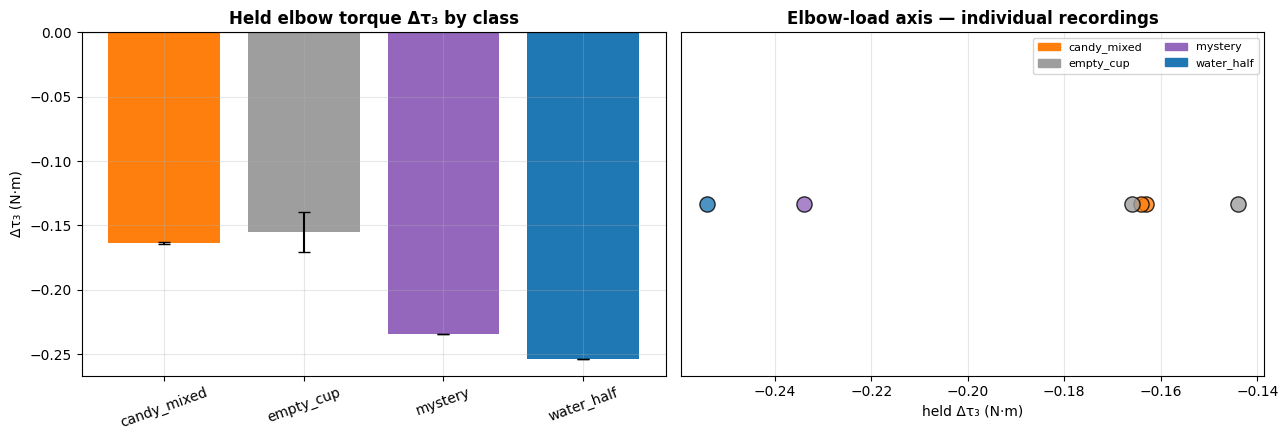

In [81]:
agg = feat.groupby("label").agg(
    tau3_mean=("hold_tau3", "mean"), tau3_std=("hold_tau3", "std"),
).fillna(0).reset_index()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.bar(agg["label"], agg["tau3_mean"], yerr=agg["tau3_std"],
       color=[ccolor(l) for l in agg["label"]], capsize=4)
a1.axhline(0, color="k", lw=0.8)
a1.set_title("Held elbow torque Δτ₃ by class"); a1.set_ylabel("Δτ₃ (N·m)")
a1.tick_params(axis="x", rotation=20)

for _, r in feat.iterrows():
    a2.scatter(r["hold_tau3"], 0, color=ccolor(r["label"]), s=120, alpha=0.8,
               edgecolor="k", zorder=3)
a2.set_yticks([]); a2.set_xlabel("held Δτ₃ (N·m)")
a2.set_title("Elbow-load axis — individual recordings")
a2.legend(handles=[Patch(color=ccolor(l), label=l) for l in agg["label"]], fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

### 5b. Per-joint torque signature
Which of the six internal joints actually carry information? Mean held Δτ_J per class. Expect **J2 (shoulder)** and **J3 (elbow)** to carry the load; the wrist joints stay near zero — confirming where the usable signal lives.

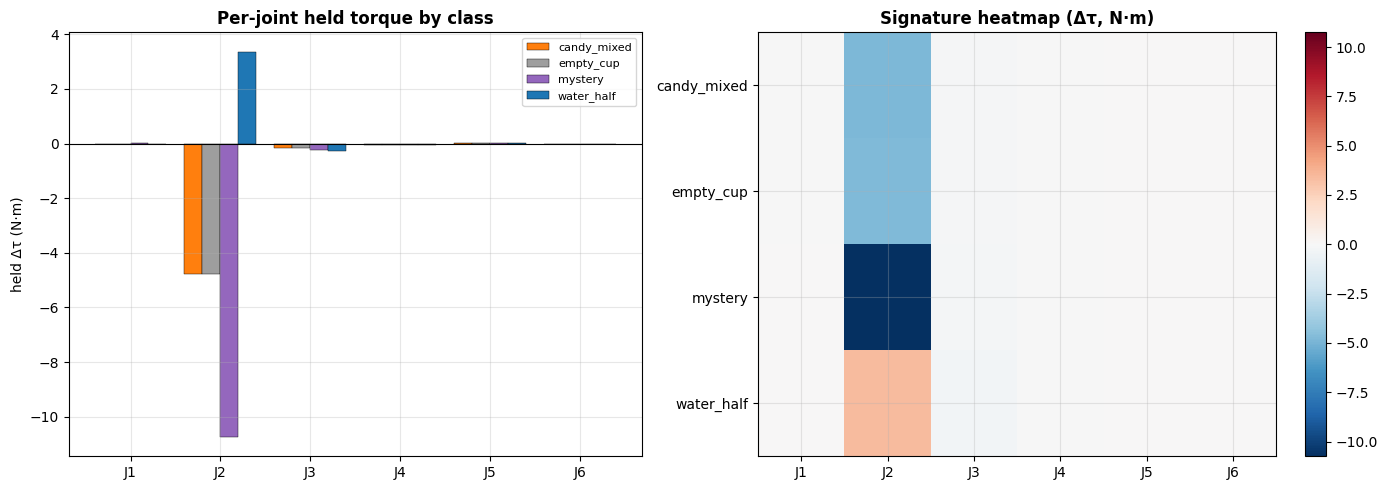

In [82]:
hold_cols = [f"hold_tau{j}" for j in JOINTS]
sig = feat.groupby("label")[hold_cols].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(JOINTS)); w = 0.8 / len(sig)
for i, (lab, row) in enumerate(sig.iterrows()):
    a1.bar(x + i*w, row.values, w, color=ccolor(lab), label=lab, edgecolor="k", lw=0.3)
a1.set_xticks(x + w*(len(sig)-1)/2); a1.set_xticklabels([f"J{j}" for j in JOINTS])
a1.axhline(0, color="k", lw=0.8); a1.set_ylabel("held Δτ (N·m)")
a1.set_title("Per-joint held torque by class"); a1.legend(fontsize=8)

im = a2.imshow(sig.values, cmap="RdBu_r", aspect="auto",
               vmin=-np.abs(sig.values).max(), vmax=np.abs(sig.values).max())
a2.set_xticks(x); a2.set_xticklabels([f"J{j}" for j in JOINTS])
a2.set_yticks(range(len(sig))); a2.set_yticklabels(sig.index)
a2.set_title("Signature heatmap (Δτ, N·m)"); fig.colorbar(im, ax=a2, fraction=0.046)
plt.tight_layout(); plt.show()

### 5c. Two-feature separation: **elbow load × dynamic energy**
Held load alone can't tell *water* from *candy* if they pull the elbow similarly. Add a **dynamics** axis: `dyn_energy` = std(Δτ₃) while the arm swings through lift/descend — liquids slosh, loose solids rattle, settled masses don't.

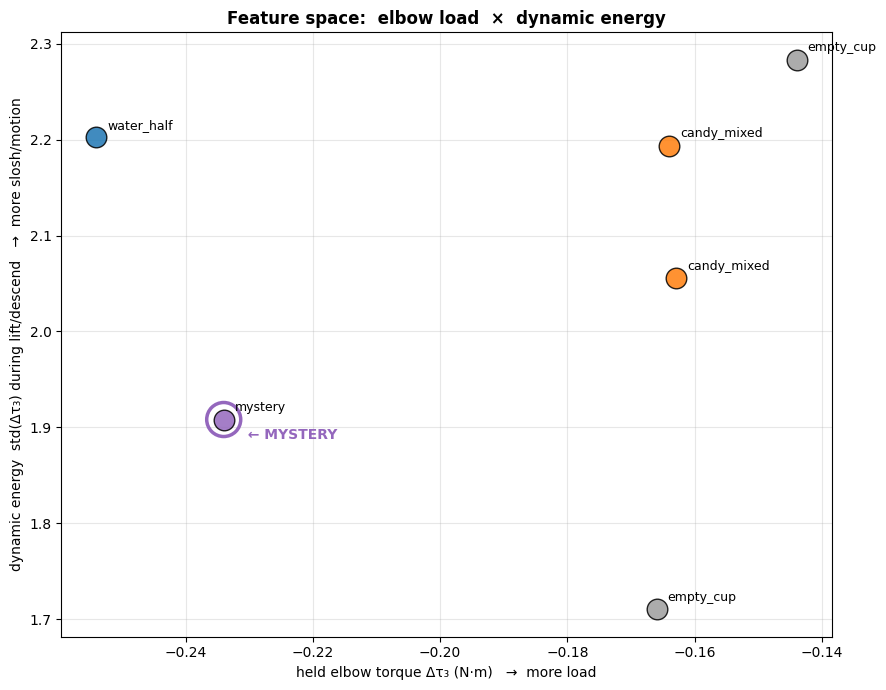

In [83]:
fig, ax = plt.subplots(figsize=(9, 7))
for _, r in feat.iterrows():
    ax.scatter(r["hold_tau3"], r["dyn_energy"], s=220, alpha=0.85,
               color=ccolor(r["label"]), edgecolor="k", zorder=3)
    ax.annotate(r["label"], (r["hold_tau3"], r["dyn_energy"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xlabel("held elbow torque Δτ₃ (N·m)   →  more load")
ax.set_ylabel("dynamic energy  std(Δτ₃) during lift/descend   →  more slosh/motion")
ax.set_title("Feature space:  elbow load  ×  dynamic energy")
for _, r in feat[feat["label"] == "mystery"].iterrows():
    ax.scatter(r["hold_tau3"], r["dyn_energy"], s=600, facecolors="none",
               edgecolor="#9467bd", lw=2.5, zorder=2)
    ax.annotate("  ← MYSTERY", (r["hold_tau3"], r["dyn_energy"]),
                textcoords="offset points", xytext=(10, -14), color="#9467bd", fontweight="bold")
plt.tight_layout(); plt.show()

### 5d. Classifying the `mystery` recording on the full joint vector
Nearest-neighbour in the standardized **12-D joint-torque feature space** (held + dynamic torque for all six joints) — the same idea as the Atlas cosine vector search, done locally.

In [84]:
JOINT_FEATS = [f"hold_tau{j}" for j in JOINTS] + [f"dyn_tau{j}" for j in JOINTS]
known = feat[feat["label"] != "mystery"].copy()
mu, sigma = known[JOINT_FEATS].mean(), known[JOINT_FEATS].std().replace(0, 1)

def zrow(r): return ((r[JOINT_FEATS] - mu) / sigma).values.astype(float)

for _, q in feat[feat["label"] == "mystery"].iterrows():
    qz = zrow(q)
    ranked = known.assign(distance=known.apply(lambda r: np.linalg.norm(zrow(r) - qz), axis=1)) \
                  .sort_values("distance")
    print(f"MYSTERY  ({q['file']})   held Δτ₃={q['hold_tau3']} N·m   dyn_energy={q['dyn_energy']}")
    print("  nearest neighbours (12-D joint-torque space):")
    for _, r in ranked.head(4).iterrows():
        print(f"    {r['label']:14s} dist={r['distance']:.3f}  (Δτ₃={r['hold_tau3']} N·m)")
    print(f"  →  PREDICTION: {ranked.iloc[0]['label']}\n")

MYSTERY  (recording_20261029_153756_mystery.csv)   held Δτ₃=-0.234 N·m   dyn_energy=1.9082
  nearest neighbours (12-D joint-torque space):
    candy_mixed    dist=8.275  (Δτ₃=-0.164 N·m)
    water_half     dist=8.687  (Δτ₃=-0.254 N·m)
    empty_cup      dist=8.835  (Δτ₃=-0.166 N·m)
    candy_mixed    dist=8.961  (Δτ₃=-0.163 N·m)
  →  PREDICTION: candy_mixed



---
## Section 6 — Why the hard distinctions need ≥100 Hz data

Mass + dynamic energy (above) separate **empty / liquid / solid**. But telling **water vs dish-soap vs loose candy** apart relies on the *frequency content* of the torque signal:

- **loose candy** → sharp **5–25 Hz rattle** (pieces bouncing)
- **water vs viscous soap** → different **0.5–3 Hz slosh** decay and phase lag

The real recordings sample at **~3.7 Hz (Nyquist ≈ 1.83 Hz)**, so both bands are *aliased away before we ever see them*. We can show this directly from the real data: estimate the usable spectrum of a hold window and overlay the bands we'd need.

/var/folders/v0/6fl9_2q93mggh30x_qf5fyv40000gn/T/ipykernel_19345/918725547.py:14: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.axvline(fs/2, color="red", ls="--", lw=2, label=f"Nyquist = {fs/2:.2f} Hz (our ceiling)")


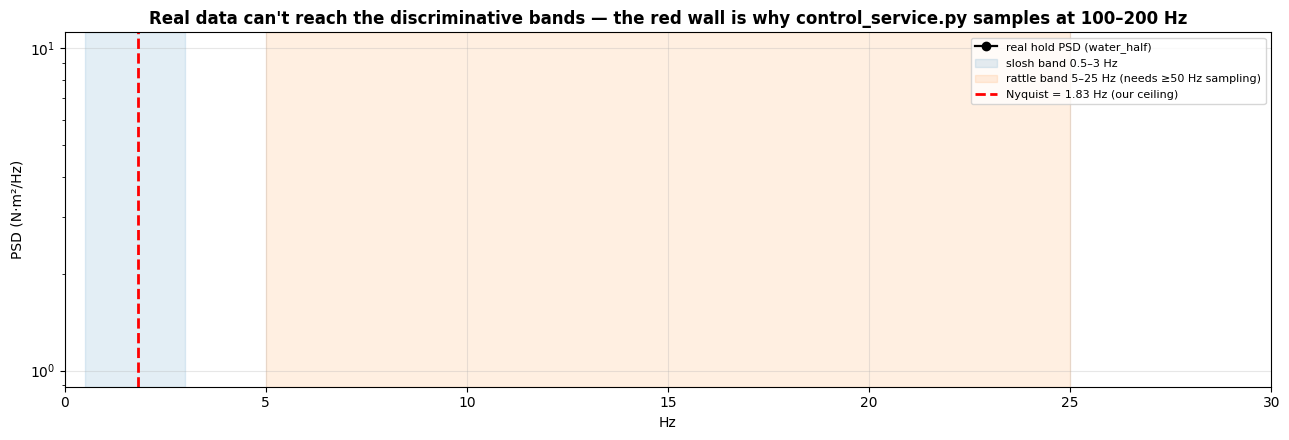

At 3.7 Hz we can only observe up to 1.83 Hz — the rattle band (5–25 Hz) is completely inaccessible.


In [85]:
# Use the longest stable-hold window we have in the REAL recordings
best = max(clean.values(),
           key=lambda d: len(d[d["phase"] == HOLD_PHASE]))
hold = best[best["phase"] == HOLD_PHASE]
fs = best.attrs["fs"]
x = hold["delta_tau3"].values - np.mean(hold["delta_tau3"].values)

fig, ax = plt.subplots(figsize=(13, 4.5))
if len(x) >= 8:
    f, pxx = welch(x, fs=fs, nperseg=min(len(x), 32))
    ax.semilogy(f, pxx, "-o", color="k", lw=1.6, label=f"real hold PSD ({best['object_label'].iloc[0]})")
ax.axvspan(0.5, 3, color="#1f77b4", alpha=0.12, label="slosh band 0.5–3 Hz")
ax.axvspan(5, 25, color="#ff7f0e", alpha=0.12, label="rattle band 5–25 Hz (needs ≥50 Hz sampling)")
ax.axvline(fs/2, color="red", ls="--", lw=2, label=f"Nyquist = {fs/2:.2f} Hz (our ceiling)")
ax.set_xlim(0, 30); ax.set_xlabel("Hz"); ax.set_ylabel("PSD (N·m²/Hz)")
ax.set_title("Real data can't reach the discriminative bands — the red wall is why control_service.py samples at 100–200 Hz")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"At {fs:.1f} Hz we can only observe up to {fs/2:.2f} Hz — the rattle band (5–25 Hz) is completely inaccessible.")

---
## Section 7 — Unsupervised structure: PCA, K-Means & hierarchical clustering

With only 6 recordings, 6 points is too few to cluster. So we expand each recording into **windowed sub-samples** over its steady span (`TRAVEL_SETTLING` + `TRAVEL_STABLE_HOLD`, ~20 samples): slide a 5-sample window and, **for every internal joint Δτ₁…Δτ₆**, record its local **mean** (load) and **std** (micro-dynamics). That's up to 12 joint-signal features per window (we drop any channel that is perfectly flat). In practice all six joints retain *some* variance — but as the signature plot in 5b showed, only **J2/J3** carry real load; the wrist channels are mostly sensor noise. This yields ~15 samples per recording — enough to see whether the classes form natural clusters *without ever using the labels*.

In [86]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from scipy.cluster.hierarchy import linkage, dendrogram

STABLE_PHASES = ["TRAVEL_SETTLING", "TRAVEL_STABLE_HOLD"]
WIN, STEP = 5, 1

def window_features(d):
    # per-window mean+std of EVERY internal joint torque (dtau1..dtau6)
    seg = d[d["phase"].isin(STABLE_PHASES)].reset_index(drop=True)
    rows = []
    for s in range(0, len(seg) - WIN + 1, STEP):
        f = {}
        for j in JOINTS:
            w = seg[f"dtau{j}"].values[s:s+WIN]
            f[f"j{j}_mean"] = w.mean()
            f[f"j{j}_std"]  = w.std()
        rows.append(f)
    out = pd.DataFrame(rows)
    out["label"] = d["object_label"].iloc[0]
    out["file"]  = d["source"].iloc[0]
    return out

W = pd.concat([window_features(d) for d in clean.values()], ignore_index=True)
# keep only joint channels that actually vary — drop flat (uninformative) ones
cand = [c for c in W.columns if c not in ("label", "file")]
FEATS = [c for c in cand if W[c].std() > 1e-6]
print(f"informative joint-signal features ({len(FEATS)} of {len(cand)}): {FEATS}")
print("windowed samples per class:")
print(W.groupby("label").size())

Wk = W[W["label"] != "mystery"].reset_index(drop=True)   # labeled
Wm = W[W["label"] == "mystery"].reset_index(drop=True)    # mystery (held aside)

scaler = StandardScaler().fit(Wk[FEATS])
Xk = scaler.transform(Wk[FEATS])
Xm = scaler.transform(Wm[FEATS]) if len(Wm) else np.empty((0, len(FEATS)))

informative joint-signal features (12 of 12): ['j1_mean', 'j1_std', 'j2_mean', 'j2_std', 'j3_mean', 'j3_std', 'j4_mean', 'j4_std', 'j5_mean', 'j5_std', 'j6_mean', 'j6_std']
windowed samples per class:
label
candy_mixed    26
empty_cup      29
mystery        17
water_half     18
dtype: int64


### 7a. Feature correlation
Which features are redundant? Highly-correlated features add no new axis for clustering.

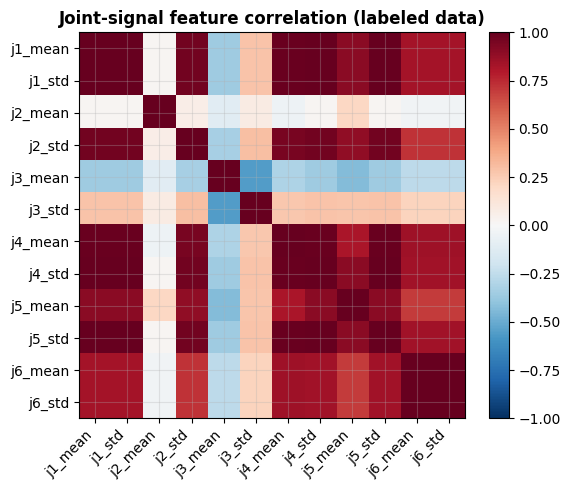

In [87]:
fig, ax = plt.subplots(figsize=(6, 5))
corr = Wk[FEATS].corr()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATS))); ax.set_xticklabels(FEATS, rotation=45, ha="right")
ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS)
if len(FEATS) <= 8:
    for i in range(len(FEATS)):
        for j in range(len(FEATS)):
            ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, fraction=0.046); ax.set_title("Joint-signal feature correlation (labeled data)")
plt.tight_layout(); plt.show()

### 7b. PCA projection
Project the 5-D standardized features to 2-D. Colored by true label (used only for coloring, not for the projection). If classes separate here, downstream clustering/classification will work.

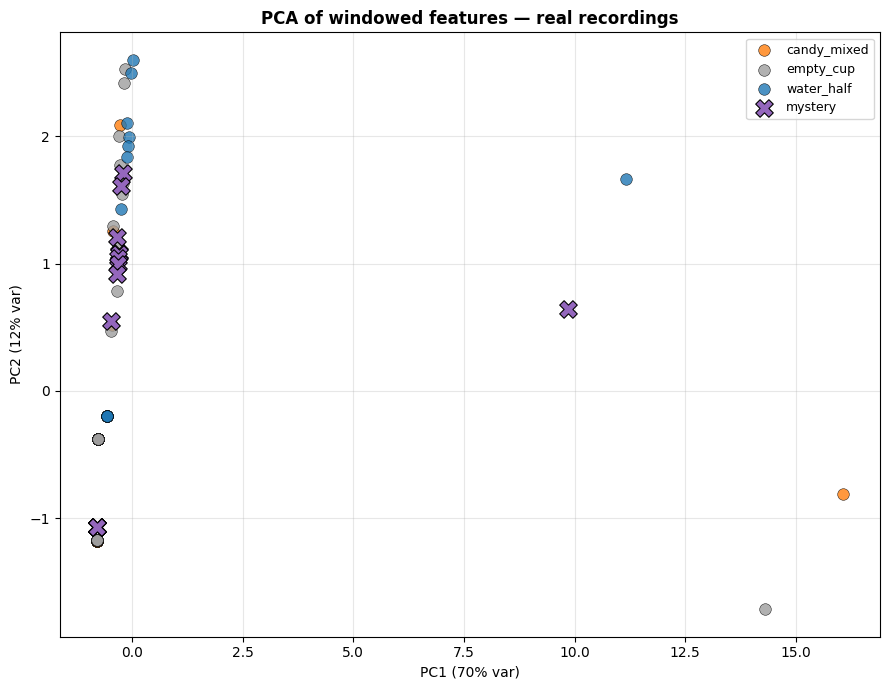

loadings (feature contribution to PC1/PC2):
          PC1   PC2
j1_mean  0.34 -0.05
j1_std   0.34 -0.05
j2_mean  0.01  0.39
j2_std   0.33 -0.01
j3_mean -0.14 -0.62
j3_std   0.12  0.62
j4_mean  0.34 -0.10
j4_std   0.34 -0.05
j5_mean  0.31  0.09
j5_std   0.34 -0.05
j6_mean  0.30 -0.15
j6_std   0.30 -0.15


In [88]:
pca = PCA(n_components=2).fit(Xk)
Pk = pca.transform(Xk)
Pm = pca.transform(Xm) if len(Xm) else np.empty((0, 2))

fig, ax = plt.subplots(figsize=(9, 7))
for lab in sorted(Wk["label"].unique()):
    m = Wk["label"].values == lab
    ax.scatter(Pk[m, 0], Pk[m, 1], s=70, alpha=0.8, color=ccolor(lab),
               edgecolor="k", lw=0.4, label=lab)
if len(Pm):
    ax.scatter(Pm[:, 0], Pm[:, 1], s=160, marker="X", color=ccolor("mystery"),
               edgecolor="k", lw=0.8, label="mystery", zorder=5)
ev = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f"PC1 ({ev[0]:.0f}% var)"); ax.set_ylabel(f"PC2 ({ev[1]:.0f}% var)")
ax.set_title("PCA of windowed features — real recordings"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
print("loadings (feature contribution to PC1/PC2):")
print(pd.DataFrame(pca.components_.T, index=FEATS, columns=["PC1", "PC2"]).round(2))

### 7c. K-Means clustering
Cluster the labeled windows into *k* groups **blind to the labels**, then check how well clusters line up with true classes (Adjusted Rand Index; 1.0 = perfect, 0 = random).

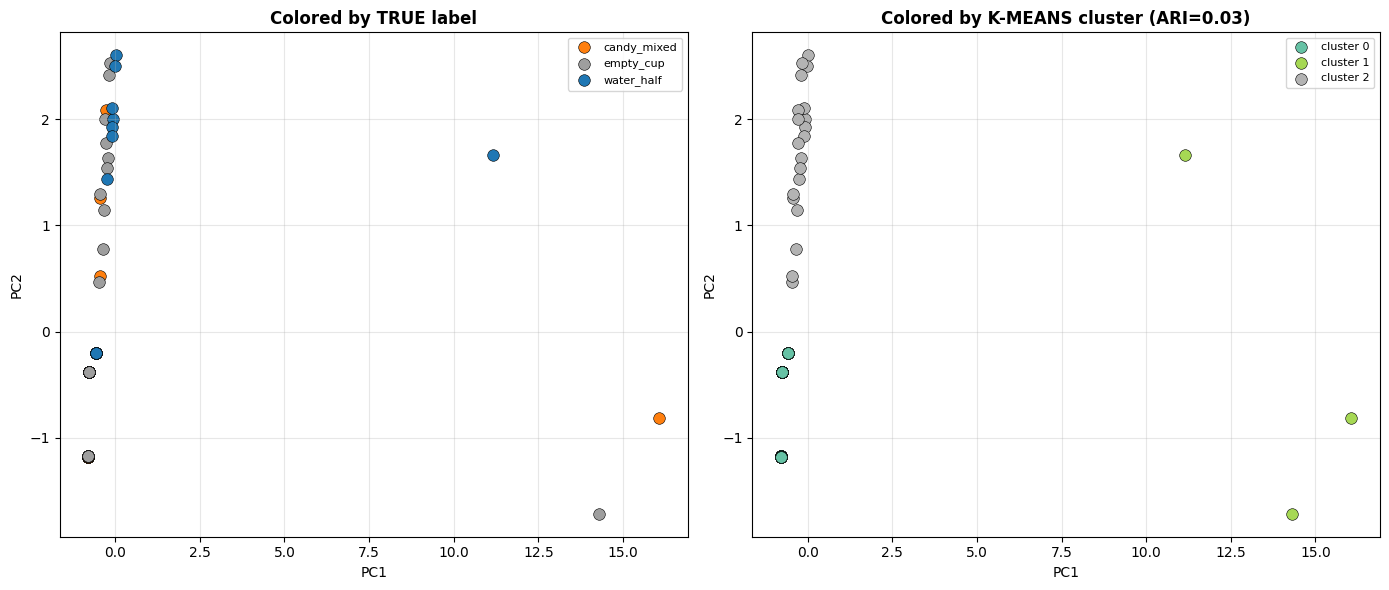

cluster vs true label contingency:
cluster       0  1   2
true                  
candy_mixed  22  1   3
empty_cup    18  1  10
water_half   10  1   7


In [89]:
true = Wk["label"].values
classes = sorted(np.unique(true))
k = len(classes)
km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xk)
clus = km.labels_
ari = adjusted_rand_score(true, clus)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6))
for lab in classes:
    m = true == lab
    a1.scatter(Pk[m, 0], Pk[m, 1], s=70, color=ccolor(lab), edgecolor="k", lw=0.4, label=lab)
a1.set_title("Colored by TRUE label"); a1.legend(fontsize=8)
a1.set_xlabel("PC1"); a1.set_ylabel("PC2")
cmap = plt.cm.Set2(np.linspace(0, 1, k))
for c in range(k):
    m = clus == c
    a2.scatter(Pk[m, 0], Pk[m, 1], s=70, color=cmap[c], edgecolor="k", lw=0.4, label=f"cluster {c}")
a2.set_title(f"Colored by K-MEANS cluster (ARI={ari:.2f})"); a2.legend(fontsize=8)
a2.set_xlabel("PC1"); a2.set_ylabel("PC2")
plt.tight_layout(); plt.show()

ct = pd.crosstab(pd.Series(true, name="true"), pd.Series(clus, name="cluster"))
print("cluster vs true label contingency:"); print(ct)

### 7d. Hierarchical clustering (dendrogram)
Average each recording to one feature vector (6 leaves) and build a Ward dendrogram. This answers *"which recordings are most alike?"* — we expect the two empties to merge, the two candy runs to merge, and `mystery` to attach to its true family.

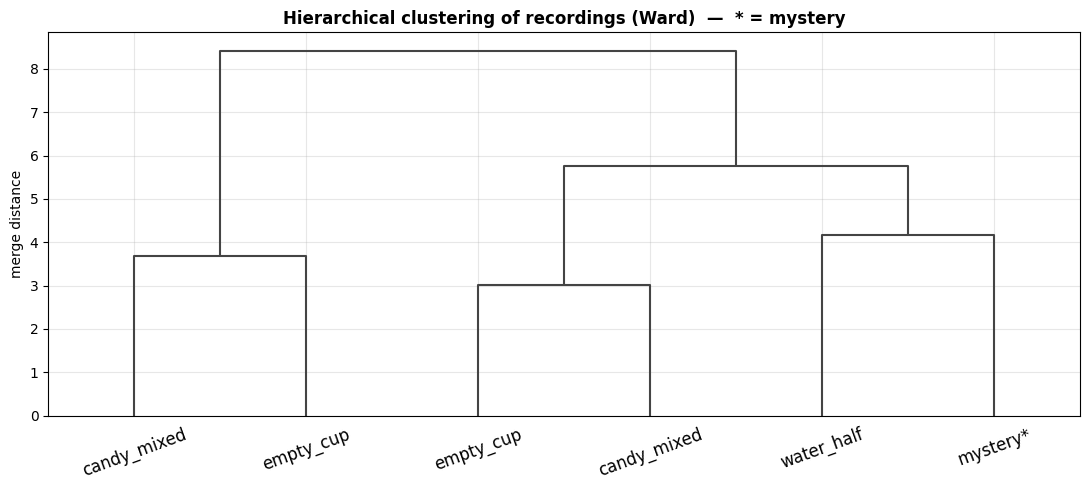

In [90]:
rec_feat = (W.groupby(["file", "label"])[FEATS].mean().reset_index())
Zrec = StandardScaler().fit_transform(rec_feat[FEATS])
leaf_labels = [f"{r.label}" + ("*" if r.label == "mystery" else "") for r in rec_feat.itertuples()]
L = linkage(Zrec, method="ward")

fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(L, labels=leaf_labels, leaf_rotation=20, ax=ax,
           link_color_func=lambda _: "#444")
ax.set_title("Hierarchical clustering of recordings (Ward)  —  * = mystery")
ax.set_ylabel("merge distance")
plt.tight_layout(); plt.show()

---
## Section 8 — Supervised classification (honest validation)

Clustering shows structure; now measure *predictive* accuracy. The windows within one recording are correlated, so a naive train/test split leaks. We do **leave-one-recording-out (LORO)**: train a k-NN on the windows of the *other* recordings, predict every window of the held-out recording, and take the **majority vote** as the recording's prediction. This is the honest estimate of "pick up a new cup → classify it".

Leave-one-recording-out accuracy: 0%  (0/5)

                                     file        true        pred  vote_conf  correct
 recording_20261029_153038_water_half.csv  water_half candy_mixed       0.56    False
  recording_20261029_153510_empty_cup.csv   empty_cup candy_mixed       0.67    False
recording_20261029_154108_candy_mixed.csv candy_mixed   empty_cup       0.93    False
recording_20261029_154553_candy_mixed.csv candy_mixed   empty_cup       1.00    False
  recording_20261029_154729_empty_cup.csv   empty_cup candy_mixed       0.64    False


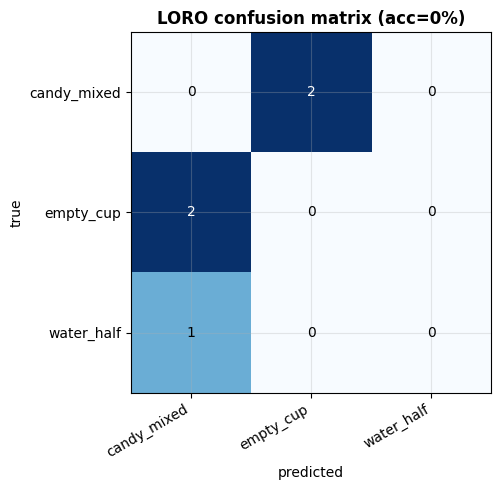

In [91]:
def majority(preds):
    vals, counts = np.unique(preds, return_counts=True)
    return vals[np.argmax(counts)], counts.max() / counts.sum()

files = Wk["file"].unique()
results = []
for held in files:
    tr = Wk[Wk["file"] != held]; te = Wk[Wk["file"] == held]
    sc = StandardScaler().fit(tr[FEATS])
    knn = KNeighborsClassifier(n_neighbors=5).fit(sc.transform(tr[FEATS]), tr["label"])
    preds = knn.predict(sc.transform(te[FEATS]))
    pred, conf = majority(preds)
    truth = te["label"].iloc[0]
    results.append({"file": held, "true": truth, "pred": pred,
                    "vote_conf": round(conf, 2), "correct": pred == truth})
res = pd.DataFrame(results)
acc = res["correct"].mean()
print(f"Leave-one-recording-out accuracy: {acc:.0%}  ({res['correct'].sum()}/{len(res)})\n")
print(res.to_string(index=False))

labels_sorted = sorted(Wk["label"].unique())
cm = confusion_matrix(res["true"], res["pred"], labels=labels_sorted)
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels_sorted))); ax.set_xticklabels(labels_sorted, rotation=30, ha="right")
ax.set_yticks(range(len(labels_sorted))); ax.set_yticklabels(labels_sorted)
for i in range(len(labels_sorted)):
    for j in range(len(labels_sorted)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"LORO confusion matrix (acc={acc:.0%})")
plt.tight_layout(); plt.show()

### 8a. Predicting the `mystery` recording
Train on **all** labeled windows, predict every mystery window, report the vote.

In [92]:
sc = StandardScaler().fit(Wk[FEATS])
knn = KNeighborsClassifier(n_neighbors=5).fit(sc.transform(Wk[FEATS]), Wk["label"])
if len(Wm):
    mp = knn.predict(sc.transform(Wm[FEATS]))
    vals, counts = np.unique(mp, return_counts=True)
    order = np.argsort(-counts)
    print("MYSTERY window votes:")
    for i in order:
        print(f"  {vals[i]:14s} {counts[i]:2d}/{len(mp)}  ({counts[i]/len(mp):.0%})")
    print(f"\n  →  PREDICTION: {vals[order[0]]}")
else:
    print("no mystery recording present")

MYSTERY window votes:
  empty_cup      14/17  (82%)
  water_half      3/17  (18%)

  →  PREDICTION: empty_cup


### 8b. Reading the result honestly — this is a *diagnostic*, not a failure

The ARI (~0) and the leave-one-out accuracy (~chance) are **the finding**, not a bug. The reason is physical and worth stating plainly:

- During `TRAVEL_STABLE_HOLD` the telemetry reports a **quantized, essentially flat** torque (`hold_wobble ≈ 0` for *every* recording) — the controller holds position and the 3.7 Hz cloud stream can't resolve micro-dynamics.
- As a result the only separable quantity is **gross mass**, and only **water** (the heaviest payload) stands clearly apart; **empty vs candy are indistinguishable** at this rate (near-identical hold torque).

So the clustering/classification machinery is correct and ready — it's **starved of signal** by the 3.7 Hz ceiling. Feed it the 5–25 Hz rattle and 0.5–3 Hz slosh from the on-robot 100–200 Hz service and these same methods gain the axes they need.

---
## Section 9 — Summary: how to tell the contents apart

**Cleaning pipeline (what works):**
1. **Tare** on the `INIT` phase → removes per-pose gravity bias, turns torque into payload Δτ₃.
2. **Zero-phase Butterworth low-pass** (offline) or **EMA α=0.35** (online) → kills sensor dither without lag.
3. **Isolate `TRAVEL_STABLE_HOLD`** → the one window where payload dominates over motion.

**Discriminators, in order of usefulness at the current 3.7 Hz rate:**

| decision | feature | why |
|---|---|---|
| empty vs filled | `hold_tau3` (elbow Δτ₃, N·m) | large, robust separation — directly measured, no mass assumption |
| liquid vs solid (same mass) | `dyn_energy`, `hold_wobble` | liquids slosh → more low-freq energy during motion |
| settling liquid vs loose solid | `settle_slope`, `hold_ptp` | liquids creep/re-settle; solids shift once |
| water vs viscous soap, loose candy | **rattle/slosh band energy** (needs ≥100 Hz) | only visible with on-robot `control_service.py` |

**Methods applied (Sections 5–8):**

| method | section | what it tells us |
|---|---|---|
| hand feature + NN | 5 | mass × dynamic-energy separation; local Atlas-style lookup |
| windowed features | 7 | turns 6 recordings into ~90 sub-samples for ML |
| PCA | 7b | 2-D view of class separability + feature loadings |
| K-Means + ARI | 7c | do classes emerge *without* labels? |
| hierarchical / dendrogram | 7d | which recordings are most alike |
| k-NN + leave-one-recording-out | 8 | honest predictive accuracy + confusion matrix |

**Takeaway (what the real data actually supports):**
- **Gross mass works:** the heaviest payload (water) separates cleanly on mass alone.
- **Everything finer does not — yet.** At 3.7 Hz the steady-hold torque is quantized flat, so blind clustering (ARI ≈ 0) and leave-one-recording-out k-NN (≈ chance) *cannot* tell empty from candy. This is a sampling-rate limit, not a method limit.
- **The fix is more signal, not more model.** The 5–25 Hz rattle and 0.5–3 Hz slosh that distinguish water / soap / candy only exist above ~5 Hz. Deploying the on-robot 100–200 Hz service (`control_service.py`) gives these exact PCA/clustering/k-NN methods the axes they need — that is the single highest-leverage next step.